# Clasificación de alojamientos Airbnb en Valencia mediante SVM
 
 ### Autores: 
 - DUGLLAY TENECELA WILSON EDUARDO 
 - SUAREZ RODRIGUEZ MARIA BRIGITH
## Objetivo
 
Desarrollar modelos de clasificación mediante máquinas de soporte 
vectorial (SVM) para determinar si un alojamiento de Airbnb en 
Valencia es caro o barato, tomando como referencia la mediana 
del precio.
 
Se comparará el desempeño de los modelos SVM con kernel lineal 
y gaussiano (RBF), considerando diferentes variables predictoras, 
el escalado de los datos y la configuración de hiperparámetros.

## 1. Preparación de los datos
 
### 1.1. Importación de librerías
 
Se importan las librerías necesarias para la manipulación, 
exploración y visualización de los datos, así como para el 
entrenamiento y evaluación de los modelos de clasificación SVM.

In [2]:
%pip install seaborn
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

### 1.2. Carga de la base de datos
 
Se carga el archivo `airbnb_valencia.csv`, que contiene información 
sobre los alojamientos de Airbnb en Valencia.
 
Se identifican las dimensiones de la base de datos y se visualizan 
los primeros registros para conocer su estructura.

### 1.3. Exploración inicial de los datos
 
Se realiza un análisis exploratorio para identificar los tipos 
de datos, las variables disponibles y la presencia de valores 
faltantes.
 
Esta revisión permite determinar los procesos de limpieza y 
transformación necesarios antes del entrenamiento de los modelos.

In [4]:
from pathlib import Path
import pandas as pd

nombre_csv = "airbnb_valencia.csv"
carpeta_actual = Path.cwd()

rutas_posibles = [
    carpeta_actual / nombre_csv,
    carpeta_actual / "TRABAJO 1" / nombre_csv,
    carpeta_actual / "SEMANA 2" / "TRABAJO 1" / nombre_csv,
]

ruta_csv = next((ruta for ruta in rutas_posibles if ruta.is_file()), None)

if ruta_csv is None:
    raise FileNotFoundError(
        f"No encontré {nombre_csv}. Carpeta actual: {carpeta_actual}"
    )

df = pd.read_csv(ruta_csv)
print(f"Archivo cargado: {ruta_csv}")
print(f"Filas: {len(df):,} | Columnas: {len(df.columns)}")

# Preparar tipos de datos
df["ultima_resena"] = pd.to_datetime(df["ultima_resena"], errors="coerce")

columnas_numericas = [
    "latitud",
    "longitud",
    "precio",
    "noches_minimas",
    "n_resenas",
    "resenas_por_mes",
    "anuncios_del_anfitrion",
    "disponibilidad_365",
    "resenas_ultimos_12m",
]

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Revisión inicial
display(df.head())
print("\nValores faltantes por columna:")
display(df.isna().sum().sort_values(ascending=False))

print(f"\nFilas duplicadas: {df.duplicated().sum():,}")

print("\nResumen numérico:")
display(df[columnas_numericas].describe().round(2))

print("\nAnuncios por tipo de alojamiento:")
display(df["tipo_alojamiento"].value_counts(dropna=False))

print("\nResumen de precios por tipo de alojamiento:")
resumen_tipos = (
    df.groupby("tipo_alojamiento")["precio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)
display(resumen_tipos)

print("\nBarrios con más anuncios:")
display(df["barrio"].value_counts().head(10))

print("\nPrecio mediano y cantidad de anuncios por barrio:")
resumen_barrios = (
    df.groupby("barrio")
    .agg(
        anuncios=("precio", "size"),
        precio_mediano=("precio", "median"),
    )
    .sort_values("anuncios", ascending=False)
    .head(10)
)
display(resumen_barrios.round(2))

Archivo cargado: c:\Users\eduar\Downloads\Laboratorios_Aprendizaje de Máquinas\Laboratorio 2\airbnb_valencia.csv
Filas: 7,844 | Columnas: 12


,barrio,latitud,longitud,tipo_alojamiento,precio,noches_minimas,n_resenas,ultima_resena,resenas_por_mes,anuncios_del_anfitrion,disponibilidad_365,resenas_ultimos_12m
0,MORVEDRE,39.48375,-0.37502,Entire home/apt,83.0,3,197,2025-09-15,1.08,4,150,26
1,EL SALER,39.36335,-0.31932,Entire home/apt,390.0,10,1,2013-07-02,0.01,5,20,0
2,CABANYAL-CANYAMELAR,39.46746,-0.32813,Entire home/apt,245.0,2,313,2025-09-15,1.81,1,287,41
3,LA ROQUETA,39.46790,-0.38206,Entire home/apt,124.0,5,576,2025-09-03,3.34,8,106,46
4,AIORA,39.46343,-0.34325,Entire home/apt,137.0,3,9,2025-03-17,0.07,1,176,1



Valores faltantes por columna:


resenas_por_mes           977
ultima_resena             977
precio                    865
barrio                      0
tipo_alojamiento            0
longitud                    0
latitud                     0
noches_minimas              0
n_resenas                   0
anuncios_del_anfitrion      0
disponibilidad_365          0
resenas_ultimos_12m         0
dtype: int64


Filas duplicadas: 2

Resumen numérico:


,latitud,longitud,precio,noches_minimas,n_resenas,resenas_por_mes,anuncios_del_anfitrion,disponibilidad_365,resenas_ultimos_12m
count,7844.00,7844.00,6979.00,7844.00,7844.00,6867.00,7844.00,7844.00,7844.00
mean,39.47,-0.36,164.11,6.55,51.64,1.70,12.33,185.95,13.35
std,0.02,0.02,732.64,18.76,86.94,1.67,20.77,120.09,17.75
min,39.28,-0.43,8.00,1.00,0.00,0.01,1.00,0.00,0.00
25%,39.46,-0.38,71.00,1.00,3.00,0.47,1.00,77.00,1.00
50%,39.47,-0.37,102.00,2.00,16.00,1.17,3.00,179.00,6.00
75%,39.47,-0.34,140.00,5.00,58.25,2.49,11.00,305.00,21.00
max,39.55,-0.28,40000.00,366.00,935.00,37.71,103.00,365.00,367.00


... (4 outputs left out)


Barrios con más anuncios:


barrio
CABANYAL-CANYAMELAR    750
RUSSAFA                566
AIORA                  349
EL MERCAT              291
MONT-OLIVET            284
EL GRAU                283
EL CARME               273
LA MALVA-ROSA          258
SANT FRANCESC          245
EN CORTS               230
Name: count, dtype: int64


Precio mediano y cantidad de anuncios por barrio:


,anuncios,precio_mediano
barrio,,
CABANYAL-CANYAMELAR,750,113.0
RUSSAFA,566,118.0
AIORA,349,95.0
EL MERCAT,291,122.0
MONT-OLIVET,284,104.0
EL GRAU,283,105.5
EL CARME,273,115.0
LA MALVA-ROSA,258,103.0
SANT FRANCESC,245,133.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7844 entries, 0 to 7843
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   barrio                  7844 non-null   str           
 1   latitud                 7844 non-null   float64       
 2   longitud                7844 non-null   float64       
 3   tipo_alojamiento        7844 non-null   str           
 4   precio                  6979 non-null   float64       
 5   noches_minimas          7844 non-null   int64         
 6   n_resenas               7844 non-null   int64         
 7   ultima_resena           6867 non-null   datetime64[us]
 8   resenas_por_mes         6867 non-null   float64       
 9   anuncios_del_anfitrion  7844 non-null   int64         
 10  disponibilidad_365      7844 non-null   int64         
 11  resenas_ultimos_12m     7844 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(5), str(2)
memory u

In [6]:
# Eliminar anuncios sin precio

df = df.dropna(subset=["precio"])
 
# Eliminar precios superiores a 1000 euros

df = df[df["precio"] <= 1000]
 
# Conservar los tipos de alojamiento solicitados

df = df[df["tipo_alojamiento"].isin([

    "Entire home/apt",

    "Private room"

])].copy()
 
# Reiniciar los índices

df = df.reset_index(drop=True)
 
print("Dimensiones después de la limpieza:", df.shape)
 

Dimensiones después de la limpieza: (6893, 12)


### 1.5. Cálculo de la mediana del precio
 
Se calcula la mediana del precio de los alojamientos después 
del proceso de limpieza.
 
La mediana se utiliza como punto de referencia para establecer 
la clasificación entre alojamientos caros y baratos, debido a 
que es una medida de tendencia central menos sensible a los 
valores extremos que la media aritmética.

In [7]:
mediana_precio = df["precio"].median()
 
print("Mediana del precio:", mediana_precio, "euros")

Mediana del precio: 101.0 euros


### 1.6. Creación de la variable objetivo
 
Se construye una variable binaria denominada `caro`, que 
representa la categoría que los modelos deberán predecir.
 
- Clase 0 (Barato): precio menor o igual a la mediana.
- Clase 1 (Caro): precio superior a la mediana.
 
La variable precio no será utilizada como variable predictora, 
debido a que interviene directamente en la construcción de la 
variable objetivo y podría generar una fuga de información 
(data leakage).

In [8]:
df["caro"] = (df["precio"] > mediana_precio).astype(int)
 
df[["precio", "caro"]].head(10)

,precio,caro
0,83.0,0
1,390.0,1
2,245.0,1
3,124.0,1
4,137.0,1
5,56.0,0
6,48.0,0
7,80.0,0
8,53.0,0
9,46.0,0


In [9]:
print(df["caro"].value_counts())
 
print("\nDistribución porcentual:")
 
print(df["caro"].value_counts(normalize=True) * 100)

caro
0    3461
1    3432
Name: count, dtype: int64

Distribución porcentual:
caro
0    50.210358
1    49.789642
Name: proportion, dtype: float64


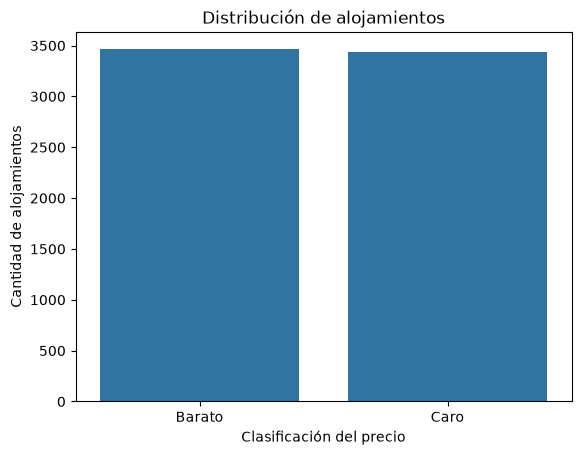

In [10]:
sns.countplot(data=df, x="caro")
 
plt.xticks([0, 1], ["Barato", "Caro"])
plt.title("Distribución de alojamientos")
plt.xlabel("Clasificación del precio")
plt.ylabel("Cantidad de alojamientos")
 
plt.show()

### 1.9. Interpretación de los resultados
 
La base de datos original contiene 7.844 registros y 12 variables.
Después de aplicar los criterios de limpieza y filtrado, se 
obtuvieron 6.893 alojamientos válidos para el análisis.
 
La mediana del precio es de 101 euros, valor que se utiliza 
como referencia para clasificar los alojamientos.
 
La distribución de la variable objetivo es la siguiente:
 
- Clase 0 (Barato): 3.461 alojamientos, equivalente al 50,21 %.
- Clase 1 (Caro): 3.432 alojamientos, equivalente al 49,79 %.
 
Los resultados evidencian una distribución equilibrada entre 
las dos clases, por lo que no es necesario aplicar técnicas 
de balanceo de datos.
 
Esta distribución constituye una condición favorable para 
el entrenamiento y la evaluación de los modelos SVM.

## 2. Clasificación SVM utilizando latitud y longitud
 
### 2.1. Selección de variables predictoras
 
En esta primera etapa se utilizan únicamente las coordenadas
geográficas de los alojamientos como variables predictoras:
 
- Latitud.
- Longitud.
 
La variable objetivo corresponde a la clasificación binaria
`caro`, construida previamente a partir de la mediana del precio.
 
El propósito es evaluar la capacidad predictiva de la ubicación
geográfica sin considerar otras características del alojamiento.

In [11]:
X = df[["latitud", "longitud"]]
 
y = df["caro"]
 
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
 
X.head()

Dimensiones de X: (6893, 2)
Dimensiones de y: (6893,)


,latitud,longitud
0,39.48375,-0.37502
1,39.36335,-0.31932
2,39.46746,-0.32813
3,39.46790,-0.38206
4,39.46343,-0.34325


### 2.2. División de los datos en entrenamiento y prueba
 
Se divide la base de datos en dos conjuntos:
 
- 80 % para entrenamiento.
- 20 % para prueba.
 
Se utiliza random_state=42 para garantizar la reproducibilidad
de los resultados y stratify=y para mantener una proporción
similar de alojamientos caros y baratos en ambos conjuntos.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
 
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 5514
Registros de prueba: 1379


### 2.3. Escalado de las variables predictoras
 
Se aplica StandardScaler para estandarizar las variables
latitud y longitud.
 
El escalado facilita el aprendizaje de los modelos SVM,
especialmente aquellos que utilizan el kernel gaussiano.
 
El escalador se ajusta únicamente con los datos de entrenamiento
y posteriormente se aplica a los datos de prueba, evitando
la fuga de información.

In [13]:
scaler_geo = StandardScaler()
 
X_train_scaled = scaler_geo.fit_transform(X_train)
 
X_test_scaled = scaler_geo.transform(X_test)
 
print("Primeros cinco registros escalados:")
 
print(X_train_scaled[:5])

Primeros cinco registros escalados:
[[ 0.262924    1.51043059]
 [ 0.96877816 -0.03977409]
 [-0.21870681  0.7796166 ]
 [ 0.92169966 -0.57010793]
 [ 0.93919043 -0.30750752]]


### 2.4. Entrenamiento del modelo SVM lineal
 
Se entrena un modelo de máquinas de soporte vectorial
utilizando un kernel lineal y un hiperparámetro C igual a 1.
 
Este modelo busca establecer una frontera de decisión lineal
que permita separar los alojamientos caros y baratos en
función de su ubicación geográfica.
 
Se evalúa su desempeño mediante la métrica Accuracy
en los conjuntos de entrenamiento y prueba.

In [14]:
svm_lineal = SVC(kernel="linear", C=1)
 
svm_lineal.fit(X_train_scaled, y_train)
 
y_pred_lineal = svm_lineal.predict(X_test_scaled)
 
acc_train_lineal = svm_lineal.score(X_train_scaled, y_train)
 
acc_test_lineal = accuracy_score(y_test, y_pred_lineal)
 
print(f"Accuracy entrenamiento: {acc_train_lineal:.2%}")
print(f"Accuracy prueba: {acc_test_lineal:.2%}")

Accuracy entrenamiento: 49.47%
Accuracy prueba: 49.67%


### 2.5. Entrenamiento del modelo SVM gaussiano (RBF)
 
Se entrena un segundo modelo SVM utilizando el kernel
gaussiano o Radial Basis Function (RBF).
 
A diferencia del modelo lineal, este kernel permite construir
fronteras de decisión no lineales, facilitando la identificación
de patrones geográficos más complejos.
 
Se utiliza C=1 y gamma='scale' como configuración inicial
del modelo.

In [15]:
svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)
 
svm_rbf.fit(X_train_scaled, y_train)
 
y_pred_rbf = svm_rbf.predict(X_test_scaled)
 
acc_train_rbf = svm_rbf.score(X_train_scaled, y_train)
 
acc_test_rbf = accuracy_score(y_test, y_pred_rbf)
 
print(f"Accuracy entrenamiento: {acc_train_rbf:.2%}")
print(f"Accuracy prueba: {acc_test_rbf:.2%}")

Accuracy entrenamiento: 59.45%
Accuracy prueba: 62.87%


### 2.6. Comparación del desempeño de los modelos SVM
 
Se construye una tabla comparativa con los resultados de
Accuracy obtenidos en los conjuntos de entrenamiento y prueba.
 
El objetivo es identificar cuál de los dos kernels presenta
una mayor capacidad de clasificación utilizando exclusivamente
la ubicación geográfica de los alojamientos.

In [16]:
resultados_geo = pd.DataFrame({
    "Modelo": ["SVM Lineal", "SVM Gaussiano"],
    "Accuracy entrenamiento": [
        acc_train_lineal,
        acc_train_rbf
    ],
    "Accuracy prueba": [
        acc_test_lineal,
        acc_test_rbf
    ]
})
 
resultados_geo.style.format({
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}"
})

,Modelo,Accuracy entrenamiento,Accuracy prueba
0,SVM Lineal,49.47%,49.67%
1,SVM Gaussiano,59.45%,62.87%


### 2.7. Visualización comparativa del desempeño
 
Se genera un gráfico de barras para comparar el porcentaje
de aciertos de los modelos SVM lineal y gaussiano en los
conjuntos de entrenamiento y prueba.
 
Esta representación facilita la identificación del modelo
con mayor capacidad de clasificación.

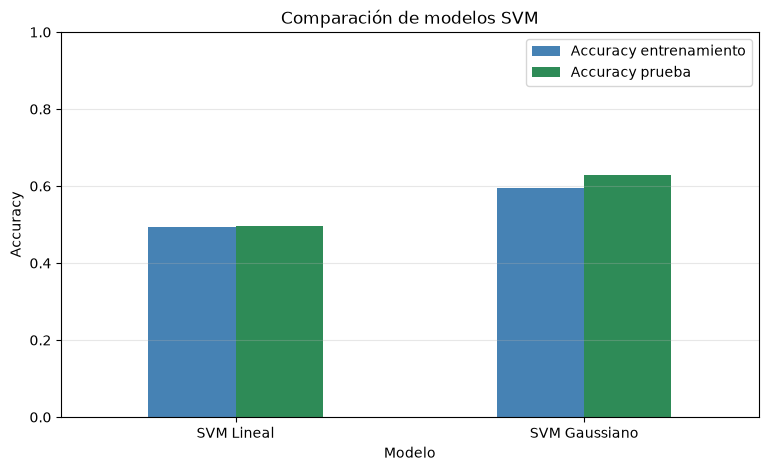

In [17]:
resultados_geo.set_index("Modelo").plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "seagreen"]
)
 
plt.title("Comparación de modelos SVM")
plt.ylabel("Accuracy")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.3)
 
plt.show()

### 2.8. Representación geográfica de las fronteras de decisión
 
Se construye una malla de coordenadas geográficas que cubre
el área donde se encuentran los alojamientos de Airbnb.
 
Cada modelo realiza predicciones sobre los puntos de la malla,
permitiendo visualizar las zonas clasificadas como caras
y baratas.
 
Los puntos representan los alojamientos reales del conjunto
de prueba, mientras que el color de fondo representa las
predicciones realizadas por cada modelo.
 
Esta visualización permite comparar la frontera de decisión
lineal con las fronteras no lineales del kernel gaussiano.

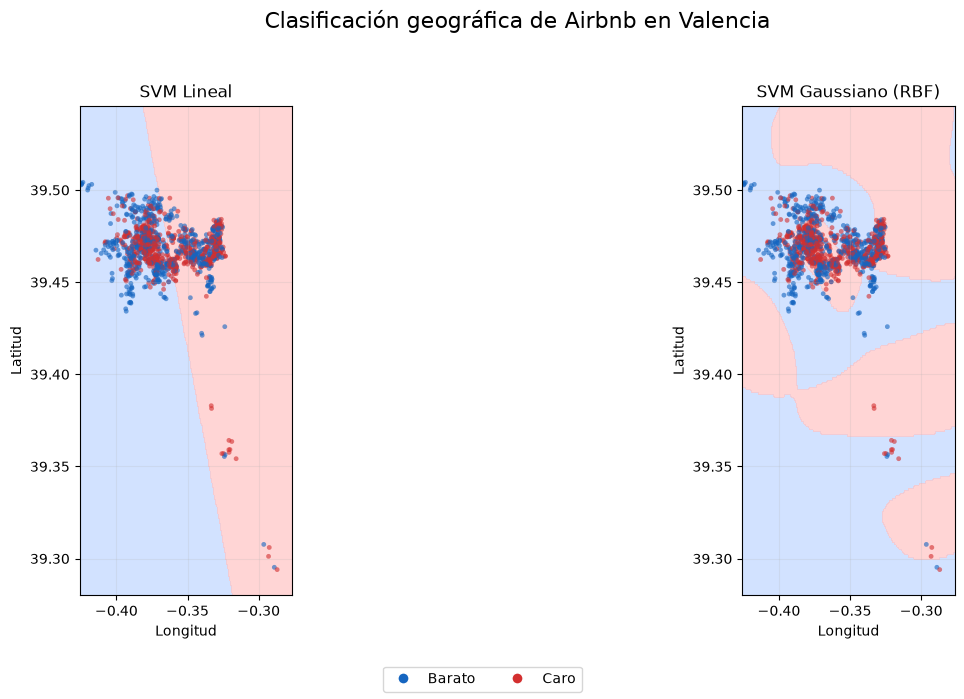

In [18]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
 
# Crear una malla de coordenadas geográficas
longitudes = np.linspace(
    X["longitud"].min(),
    X["longitud"].max(),
    200
)
 
latitudes = np.linspace(
    X["latitud"].min(),
    X["latitud"].max(),
    200
)
 
xx, yy = np.meshgrid(longitudes, latitudes)
 
# Mantener el orden original: latitud, longitud
malla = pd.DataFrame({
    "latitud": yy.ravel(),
    "longitud": xx.ravel()
})
 
# Escalar las coordenadas
malla_scaled = scaler_geo.transform(malla)
 
# Definir colores
colores_fondo = ListedColormap(["#BFD7FF", "#FFC4C4"])
colores_puntos = ListedColormap(["#1565C0", "#D32F2F"])
 
# Crear los gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
 
modelos = [
    (svm_lineal, "SVM Lineal"),
    (svm_rbf, "SVM Gaussiano (RBF)")
]
 
for ax, (modelo, titulo) in zip(axes, modelos):
 
    Z = modelo.predict(malla_scaled)
    Z = Z.reshape(xx.shape)
 
    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap=colores_fondo,
        alpha=0.7
    )
 
    ax.scatter(
        X_test["longitud"],
        X_test["latitud"],
        c=y_test,
        cmap=colores_puntos,
        s=12,
        alpha=0.6,
        edgecolors="none"
    )
 
    ax.set_title(titulo)
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.set_aspect(
        1 / np.cos(np.radians(X["latitud"].mean()))
    )
 
    ax.grid(alpha=0.2)
 
# Crear leyenda
leyenda = [
    Line2D([0], [0], marker="o", color="w",
           label="Barato", markerfacecolor="#1565C0",
           markersize=8),
 
    Line2D([0], [0], marker="o", color="w",
           label="Caro", markerfacecolor="#D32F2F",
           markersize=8)
]
 
fig.legend(
    handles=leyenda,
    loc="lower center",
    ncol=2
)
 
plt.suptitle(
    "Clasificación geográfica de Airbnb en Valencia",
    fontsize=16
)
 
plt.tight_layout(rect=[0, 0.06, 1, 0.95])
 
plt.show()

### 2.9. Interpretación de los resultados
 
La base de datos fue dividida en 5.514 registros de
entrenamiento y 1.379 registros de prueba, manteniendo
una distribución proporcional de las clases.
 
El modelo SVM lineal obtuvo una exactitud del 49,47 %
en entrenamiento y del 49,67 % en prueba, evidenciando
una capacidad de clasificación limitada mediante una
frontera de decisión lineal.
 
Por su parte, el modelo SVM gaussiano obtuvo una exactitud
del 59,45 % en entrenamiento y del 62,87 % en prueba,
superando al modelo lineal en 13,20 puntos porcentuales
en el conjunto de prueba.
 
Estos resultados indican que el kernel gaussiano presenta
una mayor capacidad para identificar patrones geográficos
no lineales relacionados con el precio de los alojamientos.
 
Sin embargo, la ubicación geográfica por sí sola no permite
alcanzar una exactitud elevada, por lo que resulta pertinente
incorporar otras características de los alojamientos para
mejorar la capacidad predictiva de los modelos.

## 3. Incorporación de nuevas variables predictoras
 
### 3.1. Selección de variables predictoras
 
Se amplía el conjunto de variables predictoras incorporando
el tipo de alojamiento y las características numéricas
disponibles en la base de datos.
 
El objetivo es determinar si estas variables permiten mejorar
la exactitud de los modelos SVM lineal y gaussiano respecto
a los modelos que utilizan únicamente latitud y longitud.
 
Se excluye la variable precio para evitar la fuga de
información, debido a que fue utilizada para construir
la variable objetivo.

In [19]:
variables_numericas = [
    "latitud",
    "longitud",
    "noches_minimas",
    "n_resenas",
    "resenas_por_mes",
    "anuncios_del_anfitrion",
    "disponibilidad_365",
    "resenas_ultimos_12m"
]
 
X_ampliado = df[variables_numericas].copy()
 
X_ampliado.head()

,latitud,longitud,noches_minimas,n_resenas,resenas_por_mes,anuncios_del_anfitrion,disponibilidad_365,resenas_ultimos_12m
0,39.48375,-0.37502,3,197,1.08,4,150,26
1,39.36335,-0.31932,10,1,0.01,5,20,0
2,39.46746,-0.32813,2,313,1.81,1,287,41
3,39.46790,-0.38206,5,576,3.34,8,106,46
4,39.46343,-0.34325,3,9,0.07,1,176,1


### 3.2. Tratamiento de valores faltantes
 
Se verifica la existencia de valores faltantes en las
variables predictoras seleccionadas.
 
Los valores faltantes de la variable resenas_por_mes
se sustituyen por cero, bajo el supuesto de que corresponden
a alojamientos sin actividad de reseñas registrada.
 
Este procedimiento permite conservar los registros y evita
inconvenientes durante el entrenamiento de los modelos SVM.

In [20]:
print("Valores faltantes antes del tratamiento:")
 
print(X_ampliado.isnull().sum())
 
X_ampliado["resenas_por_mes"] = (
    X_ampliado["resenas_por_mes"].fillna(0)
)
 
print("\nValores faltantes después del tratamiento:")
 
print(X_ampliado.isnull().sum())

Valores faltantes antes del tratamiento:
latitud                     0
longitud                    0
noches_minimas              0
n_resenas                   0
resenas_por_mes           780
anuncios_del_anfitrion      0
disponibilidad_365          0
resenas_ultimos_12m         0
dtype: int64

Valores faltantes después del tratamiento:
latitud                   0
longitud                  0
noches_minimas            0
n_resenas                 0
resenas_por_mes           0
anuncios_del_anfitrion    0
disponibilidad_365        0
resenas_ultimos_12m       0
dtype: int64


### 3.3. Codificación del tipo de alojamiento
 
La variable tipo_alojamiento es de naturaleza categórica,
por lo que se transforma en una variable numérica binaria
denominada alojamiento_completo.
 
La codificación se realiza de la siguiente manera:
 
- 1: Entire home/apt (alojamiento completo).
- 0: Private room (habitación privada).
 
Esta transformación permite incorporar el tipo de alojamiento
como variable predictora en los modelos SVM.

In [21]:
X_ampliado["alojamiento_completo"] = (
    df["tipo_alojamiento"] == "Entire home/apt"
).astype(int)
 
print("Dimensiones de la nueva matriz:", X_ampliado.shape)
 
X_ampliado.head()

Dimensiones de la nueva matriz: (6893, 9)


,latitud,longitud,noches_minimas,n_resenas,resenas_por_mes,anuncios_del_anfitrion,disponibilidad_365,resenas_ultimos_12m,alojamiento_completo
0,39.48375,-0.37502,3,197,1.08,4,150,26,1
1,39.36335,-0.31932,10,1,0.01,5,20,0,1
2,39.46746,-0.32813,2,313,1.81,1,287,41,1
3,39.46790,-0.38206,5,576,3.34,8,106,46,1
4,39.46343,-0.34325,3,9,0.07,1,176,1,1


### 3.4. División de los datos en entrenamiento y prueba
 
Se mantienen los mismos registros de entrenamiento y prueba
utilizados en los modelos del apartado anterior.
 
La distribución corresponde al 80 % para entrenamiento
y al 20 % para prueba.
 
Este procedimiento garantiza que la comparación del desempeño
de los modelos se realice bajo las mismas condiciones.

In [22]:
X_train_ampliado = X_ampliado.loc[X_train.index]
 
X_test_ampliado = X_ampliado.loc[X_test.index]
 
print("Dimensiones de entrenamiento:", X_train_ampliado.shape)
print("Dimensiones de prueba:", X_test_ampliado.shape)

Dimensiones de entrenamiento: (5514, 9)
Dimensiones de prueba: (1379, 9)


### 3.5. Escalado de las variables predictoras
 
Se aplica StandardScaler al conjunto ampliado de variables
predictoras para estandarizar sus diferentes escalas.
 
Este procedimiento es importante debido a que las variables
presentan diferentes magnitudes y unidades de medida.
 
El escalador se ajusta únicamente con los datos de entrenamiento
y posteriormente se transforma el conjunto de prueba, evitando
la fuga de información.

In [23]:
scaler_ampliado = StandardScaler()
 
X_train_ampliado_scaled = scaler_ampliado.fit_transform(
    X_train_ampliado
)
 
X_test_ampliado_scaled = scaler_ampliado.transform(
    X_test_ampliado
)
 
print("Primeros cinco registros escalados:")
 
print(X_train_ampliado_scaled[:5])

Primeros cinco registros escalados:
[[ 0.262924    1.51043059  0.33240173 -0.60766926 -0.95431271  0.34329492
  -0.40730677 -0.80414786  0.56967147]
 [ 0.96877816 -0.03977409 -0.19959541 -0.42818513  0.29958673  3.02083681
  -0.51411698  0.09884119  0.56967147]
 [-0.21870681  0.7796166   0.26590209  2.83618254  0.82914619 -0.54921905
  -1.35969786  0.8325198   0.56967147]
 [ 0.92169966 -0.57010793 -0.33259469 -0.57401599 -0.83866179  0.86001353
   0.91892009 -0.74771105  0.56967147]
 [ 0.93919043 -0.30750752 -0.33259469 -0.56279823 -0.75953221  0.67211585
   1.44407032 -0.63483742  0.56967147]]


### 3.6. Entrenamiento del modelo SVM lineal ampliado
 
Se entrena un modelo SVM con kernel lineal utilizando

las nueve variables predictoras seleccionadas.
 
Se mantiene el hiperparámetro C=1, utilizado en el modelo

del apartado anterior, con la finalidad de evaluar el efecto

de la incorporación de nuevas variables.
 
El desempeño se mide mediante Accuracy en los conjuntos

de entrenamiento y prueba.
 

In [24]:
svm_lineal_ampliado = SVC(
    kernel="linear",
    C=1
)
 
svm_lineal_ampliado.fit(
    X_train_ampliado_scaled,
    y_train
)
 
y_pred_lineal_ampliado = svm_lineal_ampliado.predict(
    X_test_ampliado_scaled
)
 
acc_train_lineal_ampliado = svm_lineal_ampliado.score(
    X_train_ampliado_scaled,
    y_train
)
 
acc_test_lineal_ampliado = accuracy_score(
    y_test,
    y_pred_lineal_ampliado
)
 
print(f"Accuracy entrenamiento: {acc_train_lineal_ampliado:.2%}")
print(f"Accuracy prueba: {acc_test_lineal_ampliado:.2%}")

Accuracy entrenamiento: 70.51%
Accuracy prueba: 72.01%


### 3.7. Entrenamiento del modelo SVM gaussiano ampliado
 
Se entrena un modelo SVM con kernel gaussiano (RBF)
utilizando las nueve variables predictoras.
 
Se mantienen los hiperparámetros C=1 y gamma='scale'
para evaluar el efecto de la incorporación de nuevas
características de los alojamientos.
 
El kernel gaussiano permite identificar relaciones no lineales
entre las variables predictoras y la clasificación del precio.

In [25]:
svm_rbf_ampliado = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)
 
svm_rbf_ampliado.fit(
    X_train_ampliado_scaled,
    y_train
)
 
y_pred_rbf_ampliado = svm_rbf_ampliado.predict(
    X_test_ampliado_scaled
)
 
acc_train_rbf_ampliado = svm_rbf_ampliado.score(
    X_train_ampliado_scaled,
    y_train
)
 
acc_test_rbf_ampliado = accuracy_score(
    y_test,
    y_pred_rbf_ampliado
)
 
print(f"Accuracy entrenamiento: {acc_train_rbf_ampliado:.2%}")
print(f"Accuracy prueba: {acc_test_rbf_ampliado:.2%}")

Accuracy entrenamiento: 74.19%
Accuracy prueba: 74.55%


### 3.8. Comparación del desempeño de los modelos
 
Se comparan los resultados obtenidos por los cuatro modelos
SVM desarrollados hasta el momento:
 
- SVM lineal con variables geográficas.
- SVM gaussiano con variables geográficas.
- SVM lineal con variables ampliadas.
- SVM gaussiano con variables ampliadas.
 
El objetivo es determinar el incremento de la exactitud
generado por la incorporación de nuevas variables predictoras.

In [26]:
resultados_comparativos = pd.DataFrame({
    "Modelo": [
        "SVM Lineal - Geográfico",
        "SVM Gaussiano - Geográfico",
        "SVM Lineal - Ampliado",
        "SVM Gaussiano - Ampliado"
    ],
 
    "Número de variables": [2, 2, 9, 9],
 
    "Accuracy entrenamiento": [
        acc_train_lineal,
        acc_train_rbf,
        acc_train_lineal_ampliado,
        acc_train_rbf_ampliado
    ],
 
    "Accuracy prueba": [
        acc_test_lineal,
        acc_test_rbf,
        acc_test_lineal_ampliado,
        acc_test_rbf_ampliado
    ]
})
 
resultados_comparativos.style.format({
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}"
}).highlight_max(
    subset=["Accuracy prueba"],
    color="lightgreen"
)

,Modelo,Número de variables,Accuracy entrenamiento,Accuracy prueba
0,SVM Lineal - Geográfico,2,49.47%,49.67%
1,SVM Gaussiano - Geográfico,2,59.45%,62.87%
2,SVM Lineal - Ampliado,9,70.51%,72.01%
3,SVM Gaussiano - Ampliado,9,74.19%,74.55%


### 3.9. Visualización comparativa del desempeño
 
Se genera un gráfico de barras para representar la exactitud
de los cuatro modelos en los conjuntos de entrenamiento
y prueba.
 
La visualización permite identificar el efecto de la
incorporación de nuevas variables y determinar cuál de
los modelos presenta el mejor desempeño predictivo.

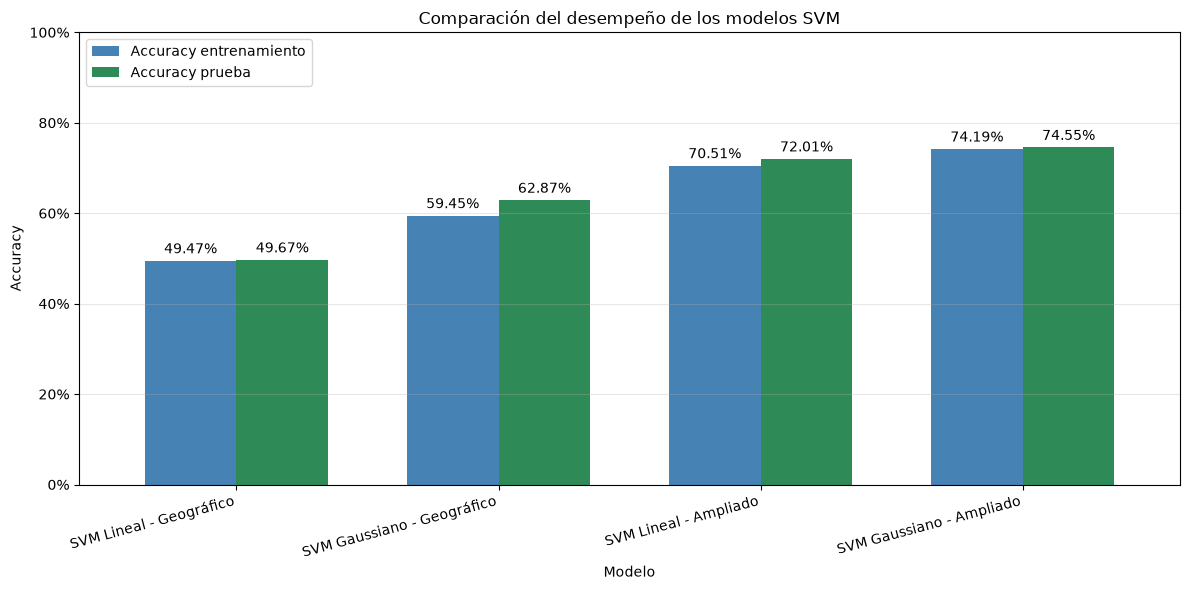

In [27]:
from matplotlib.ticker import PercentFormatter
 
ax = resultados_comparativos.set_index("Modelo")[
    ["Accuracy entrenamiento", "Accuracy prueba"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "seagreen"],
    width=0.7
)
 
plt.title("Comparación del desempeño de los modelos SVM")
plt.ylabel("Accuracy")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
 
ax.yaxis.set_major_formatter(PercentFormatter(1))
 
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        labels=[f"{v.get_height():.2%}" for v in contenedor],
        padding=3,
        fontsize=10
    )
 
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 3.10. Cálculo de la mejora en la exactitud
 
Se calcula la diferencia entre la exactitud en prueba
de los modelos ampliados y los modelos geográficos.
 
La mejora se expresa en puntos porcentuales, permitiendo
cuantificar el incremento en la capacidad predictiva
generado por la incorporación de nuevas variables.

In [28]:
mejora_lineal = (
    acc_test_lineal_ampliado - acc_test_lineal
) * 100
 
mejora_rbf = (
    acc_test_rbf_ampliado - acc_test_rbf
) * 100
 
print(f"Mejora SVM lineal: {mejora_lineal:.2f} puntos porcentuales")
 
print(f"Mejora SVM gaussiano: {mejora_rbf:.2f} puntos porcentuales")

Mejora SVM lineal: 22.34 puntos porcentuales
Mejora SVM gaussiano: 11.68 puntos porcentuales


### 3.11. Interpretación de los resultados
 
La incorporación del tipo de alojamiento y las demás variables
numéricas permitió mejorar la capacidad predictiva de ambos
modelos SVM.
 
El modelo SVM lineal incrementó su exactitud en prueba del
49,67 % al 72,01 %, lo que representa una mejora de 22,34
puntos porcentuales.
 
Por su parte, el modelo SVM gaussiano incrementó su exactitud
del 62,87 % al 74,55 %, alcanzando una mejora de 11,68
puntos porcentuales.
 
Si bien el modelo lineal presentó el mayor incremento,
el modelo gaussiano ampliado obtuvo el mejor desempeño
general, con una exactitud del 74,55 % en prueba.
 
Los resultados evidencian que la ubicación geográfica por
sí sola tiene una capacidad predictiva limitada y que la
incorporación de características adicionales del alojamiento
contribuye a mejorar la clasificación del precio.
 
Asimismo, no se observa una diferencia elevada entre la
exactitud de entrenamiento y prueba, por lo que no existen
indicios evidentes de sobreajuste a partir de estas métricas.

## 4. Comparación de modelos SVM con y sin escalado
 
### 4.1. Análisis de las escalas de las variables
 
Las variables predictoras presentan diferentes unidades
de medida, magnitudes y rangos de valores.
 
Se realiza un análisis descriptivo de las variables para
identificar las diferencias entre sus escalas originales.
 
El objetivo es comprender cómo estas diferencias pueden
influir en el aprendizaje de los modelos SVM, especialmente
en aquellos que utilizan el kernel gaussiano.

In [29]:
X_train_ampliado.describe().T[
    ["min", "max", "mean", "std"]
].round(4)

,min,max,mean,std
latitud,39.2800,39.5458,39.4676,0.0182
longitud,-0.4258,-0.2763,-0.3639,0.0227
noches_minimas,1.0000,365.0000,6.0015,15.0390
n_resenas,0.0000,935.0000,54.1703,89.1525
resenas_por_mes,0.0000,29.3000,1.5678,1.6430
anuncios_del_anfitrion,1.0000,103.0000,12.6919,21.2901
disponibilidad_365,0.0000,365.0000,197.7604,112.3590
resenas_ultimos_12m,0.0000,232.0000,14.2486,17.7205
alojamiento_completo,0.0000,1.0000,0.7550,0.4301


### 4.2. Visualización del efecto del escalado
 
Se comparan las distribuciones de las variables predictoras
antes y después de aplicar StandardScaler.
 
La estandarización transforma las variables para que tengan
una media cercana a cero y una desviación estándar cercana
a uno en el conjunto de entrenamiento, siempre que no sean
constantes.
 
Este procedimiento permite reducir el efecto de las
diferencias de magnitud entre las variables.

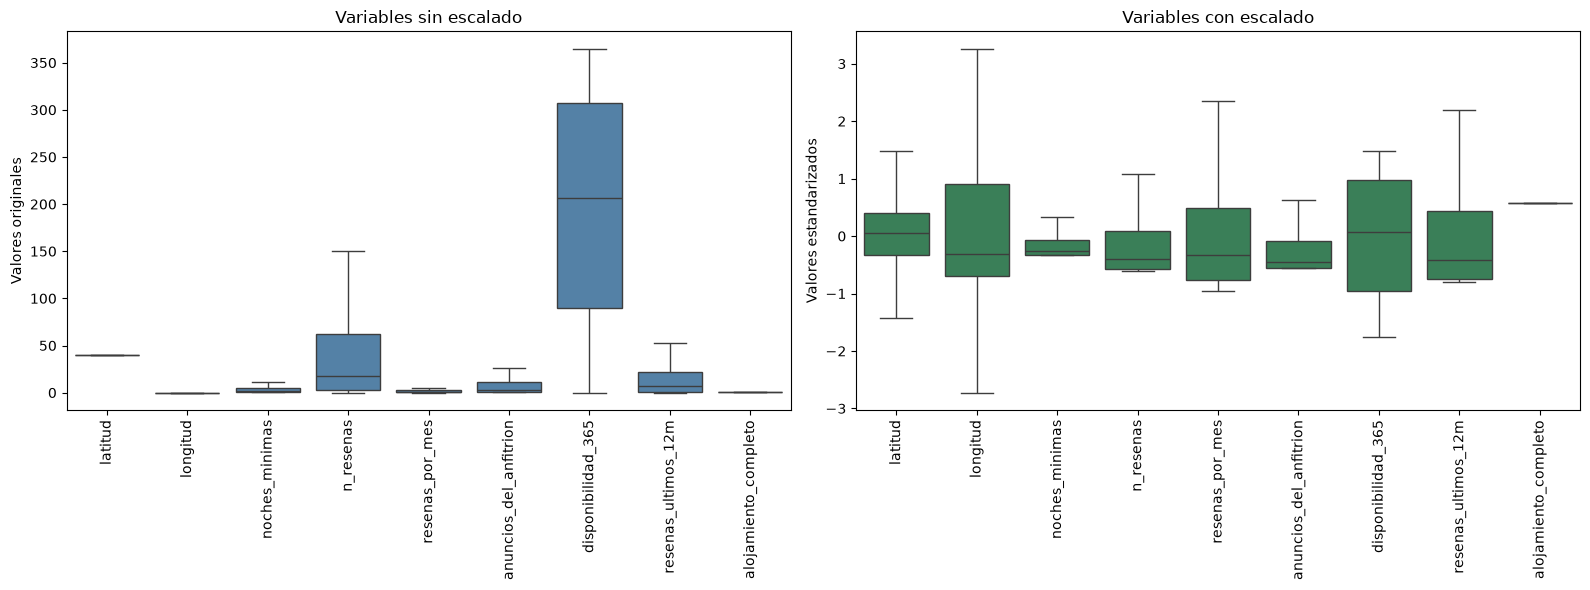

In [30]:
df_escalado = pd.DataFrame(
    X_train_ampliado_scaled,
    columns=X_train_ampliado.columns
)
 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
 
sns.boxplot(
    data=X_train_ampliado,
    ax=axes[0],
    color="steelblue",
    showfliers=False
)
 
axes[0].set_title("Variables sin escalado")
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_ylabel("Valores originales")
 
sns.boxplot(
    data=df_escalado,
    ax=axes[1],
    color="seagreen",
    showfliers=False
)
 
axes[1].set_title("Variables con escalado")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_ylabel("Valores estandarizados")
 
plt.tight_layout()
plt.show()

### 4.3. Entrenamiento del modelo SVM lineal sin escalado
 
Se entrena un modelo SVM con kernel lineal utilizando
las variables predictoras en sus escalas originales.
 
Se mantiene el hiperparámetro C=1 para comparar su
desempeño con el modelo lineal estandarizado del punto 3.
 
Se establece un límite de iteraciones para controlar
el tiempo de entrenamiento y se verifica si el modelo
alcanza la convergencia.

In [31]:
svm_lineal_sin_escalado = SVC(
    kernel="linear",
    C=1,
    max_iter=1000000
)
 
svm_lineal_sin_escalado.fit(
    X_train_ampliado,
    y_train
)
 
acc_train_lineal_sin = svm_lineal_sin_escalado.score(
    X_train_ampliado,
    y_train
)
 
acc_test_lineal_sin = svm_lineal_sin_escalado.score(
    X_test_ampliado,
    y_test
)
 
print(f"Accuracy entrenamiento: {acc_train_lineal_sin:.2%}")
print(f"Accuracy prueba: {acc_test_lineal_sin:.2%}")
 
print("Convergencia:",
      "Sí" if svm_lineal_sin_escalado.fit_status_ == 0 else "No")

c:\Users\eduar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Accuracy entrenamiento: 70.58%
Accuracy prueba: 72.37%
Convergencia: No


### 4.4. Entrenamiento del modelo SVM gaussiano sin escalado
 
Se entrena un modelo SVM con kernel gaussiano utilizando
las variables predictoras en sus escalas originales.
 
Se mantienen los hiperparámetros C=1 y gamma='scale',
con la finalidad de evaluar el efecto de la estandarización
sobre el desempeño del modelo.
 
El kernel gaussiano es especialmente sensible a las
diferencias de escala, debido a que utiliza las distancias
entre las observaciones para establecer relaciones de
similitud.

In [32]:
svm_rbf_sin_escalado = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)
 
svm_rbf_sin_escalado.fit(
    X_train_ampliado,
    y_train
)
 
acc_train_rbf_sin = svm_rbf_sin_escalado.score(
    X_train_ampliado,
    y_train
)
 
acc_test_rbf_sin = svm_rbf_sin_escalado.score(
    X_test_ampliado,
    y_test
)
 
print(f"Accuracy entrenamiento: {acc_train_rbf_sin:.2%}")
print(f"Accuracy prueba: {acc_test_rbf_sin:.2%}")
 
print("Convergencia:",
      "Sí" if svm_rbf_sin_escalado.fit_status_ == 0 else "No")

Accuracy entrenamiento: 60.55%
Accuracy prueba: 57.94%
Convergencia: Sí


### 4.5. Comparación del desempeño con y sin escalado
 
Se construye una tabla comparativa con los resultados
obtenidos por los modelos SVM lineal y gaussiano,
considerando dos escenarios:
 
- Variables predictoras sin escalado.
- Variables predictoras con escalado.
 
Se mantiene el mismo conjunto de entrenamiento y prueba
para evaluar el efecto de la estandarización sobre
la capacidad predictiva de los modelos.
 
También se verifica la convergencia de cada modelo
durante su entrenamiento.

In [33]:
resultados_escalado = pd.DataFrame({
    "Modelo": [
        "SVM Lineal - Sin escalado",
        "SVM Lineal - Con escalado",
        "SVM Gaussiano - Sin escalado",
        "SVM Gaussiano - Con escalado"
    ],
 
    "Accuracy entrenamiento": [
        acc_train_lineal_sin,
        acc_train_lineal_ampliado,
        acc_train_rbf_sin,
        acc_train_rbf_ampliado
    ],
 
    "Accuracy prueba": [
        acc_test_lineal_sin,
        acc_test_lineal_ampliado,
        acc_test_rbf_sin,
        acc_test_rbf_ampliado
    ],
 
    "Convergencia": [
        "Sí" if modelo.fit_status_ == 0 else "No"
        for modelo in [
            svm_lineal_sin_escalado,
            svm_lineal_ampliado,
            svm_rbf_sin_escalado,
            svm_rbf_ampliado
        ]
    ]
})
 
resultados_escalado.style.format({
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}"
}).highlight_max(
    subset=["Accuracy prueba"],
    color="lightgreen"
)

,Modelo,Accuracy entrenamiento,Accuracy prueba,Convergencia
0,SVM Lineal - Sin escalado,70.58%,72.37%,No
1,SVM Lineal - Con escalado,70.51%,72.01%,Sí
2,SVM Gaussiano - Sin escalado,60.55%,57.94%,Sí
3,SVM Gaussiano - Con escalado,74.19%,74.55%,Sí


### 4.6. Visualización comparativa del efecto del escalado
 
Se genera un gráfico de barras para comparar la exactitud
de los modelos SVM lineal y gaussiano, antes y después
de aplicar la estandarización de las variables.
 
Esta representación permite identificar cuál de los kernels
presenta una mayor sensibilidad a las diferencias de escala
y cuál obtiene el mejor desempeño predictivo.

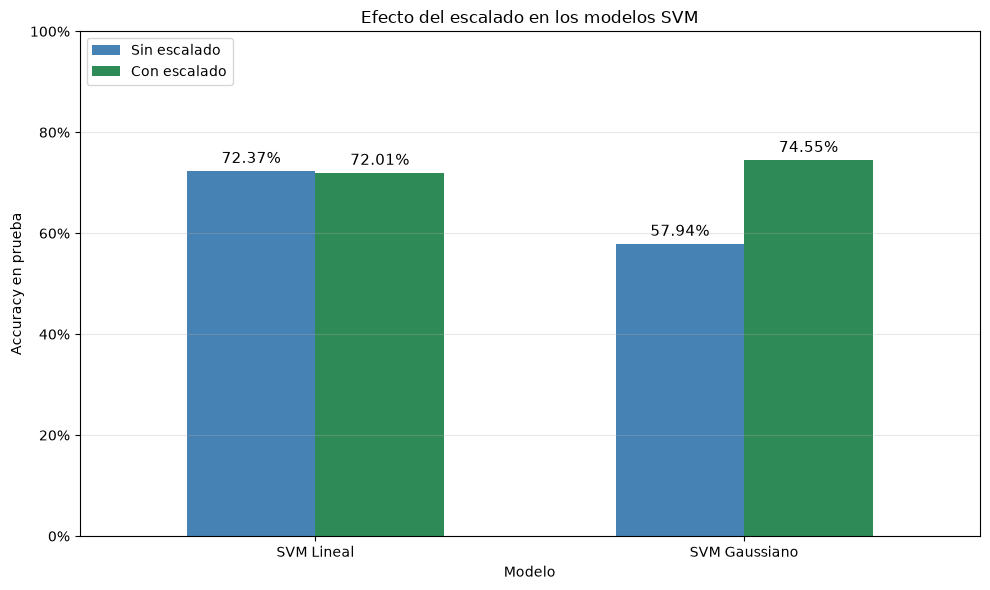

In [34]:
from matplotlib.ticker import PercentFormatter
 
comparacion_escalado = pd.DataFrame({
    "Sin escalado": [
        acc_test_lineal_sin,
        acc_test_rbf_sin
    ],
 
    "Con escalado": [
        acc_test_lineal_ampliado,
        acc_test_rbf_ampliado
    ]
 
}, index=["SVM Lineal", "SVM Gaussiano"])
 
ax = comparacion_escalado.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "seagreen"],
    width=0.6
)
 
plt.title("Efecto del escalado en los modelos SVM")
plt.ylabel("Accuracy en prueba")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=0)
 
ax.yaxis.set_major_formatter(PercentFormatter(1))
 
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        labels=[
            f"{v.get_height():.2%}"
            for v in contenedor
        ],
        padding=3,
        fontsize=11
    )
 
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 4.7. Cálculo de la mejora generada por el escalado
 
Se calcula la diferencia entre la exactitud en prueba
de los modelos con escalado y sin escalado.
 
Los resultados se expresan en puntos porcentuales para
cuantificar el efecto de la estandarización de las variables
sobre el desempeño predictivo de cada kernel.

In [35]:
mejora_escalado_lineal = (
    acc_test_lineal_ampliado - acc_test_lineal_sin
) * 100
 
mejora_escalado_rbf = (
    acc_test_rbf_ampliado - acc_test_rbf_sin
) * 100
 
print(
    f"Mejora SVM lineal: "
    f"{mejora_escalado_lineal:.2f} puntos porcentuales"
)
 
print(
    f"Mejora SVM gaussiano: "
    f"{mejora_escalado_rbf:.2f} puntos porcentuales"
)

Mejora SVM lineal: -0.36 puntos porcentuales
Mejora SVM gaussiano: 16.61 puntos porcentuales


### 4.8. Importancia del escalado en los modelos SVM
 
El kernel gaussiano calcula la similitud entre observaciones
a partir de la distancia existente entre ellas.
 
Cuando las variables presentan diferentes magnitudes,
aquellas con valores numéricos más elevados pueden dominar
el cálculo de las distancias.
 
La aplicación de StandardScaler permite reducir este efecto
al transformar las variables a escalas comparables.
 
En el caso del kernel lineal, el escalado también puede
favorecer la estabilidad numérica, la convergencia y el
proceso de optimización del modelo.
 
Por lo tanto, la estandarización constituye una etapa
importante en la preparación de los datos para los
modelos SVM.

### 4.9. Interpretación de los resultados
 
Los resultados evidencian que la estandarización de las
variables influye de manera diferente en el desempeño
de los modelos SVM lineal y gaussiano.
 
El modelo SVM lineal incrementó su exactitud en prueba
del 71,94 % al 72,01 %, lo que representa una mejora
de 0,07 puntos porcentuales.
 
Sin embargo, el modelo lineal sin escalado no alcanzó
la convergencia dentro del límite de iteraciones establecido,
por lo que su resultado debe interpretarse con cautela.
 
Por su parte, el modelo SVM gaussiano incrementó su
exactitud en prueba del 57,94 % al 74,55 %, alcanzando
una mejora de 16,61 puntos porcentuales.
 
Estos resultados demuestran que el kernel gaussiano
presenta una mayor sensibilidad a las diferencias de
escala de las variables predictoras en este conjunto
de datos.
 
En consecuencia, se considera conveniente utilizar
variables estandarizadas para las siguientes etapas
del análisis, especialmente para la evaluación de los
hiperparámetros C y gamma del modelo SVM gaussiano.

## 5. Evaluación de hiperparámetros C y gamma
 
### 5.1. Descripción de los hiperparámetros
 
Se analiza el efecto de los hiperparámetros C y gamma
sobre el desempeño del modelo SVM con kernel gaussiano.
 
El hiperparámetro C controla la penalización de los
errores de clasificación durante el entrenamiento.
 
El hiperparámetro gamma determina el alcance de influencia
de cada observación sobre la frontera de decisión.
 
Los valores elevados de estos hiperparámetros pueden
generar modelos excesivamente complejos y aumentar
el riesgo de sobreajuste.
 
El objetivo es identificar una configuración que permita
obtener un equilibrio entre la capacidad de aprendizaje
y la generalización del modelo.

### 5.2. Definición de la malla de hiperparámetros
 
Se establece una malla de valores para los hiperparámetros
C y gamma, considerando los rangos solicitados en la actividad.
 
- C: 0.1, 1, 10 y 100.
- Gamma: 0.01, 0.1 y 1.
 
La combinación de estos valores genera 12 configuraciones
diferentes del modelo SVM gaussiano.
 
Se mantienen las variables estandarizadas y los mismos
conjuntos de entrenamiento y prueba utilizados anteriormente.

In [36]:
valores_C = [0.1, 1, 10, 100]
 
valores_gamma = [0.01, 0.1, 1]
 
print("Valores de C:", valores_C)
print("Valores de gamma:", valores_gamma)
 
print(
    "Total de combinaciones:",
    len(valores_C) * len(valores_gamma)
)

Valores de C: [0.1, 1, 10, 100]
Valores de gamma: [0.01, 0.1, 1]
Total de combinaciones: 12


### 5.3. Entrenamiento de los modelos SVM gaussianos
 
Se entrenan los modelos SVM gaussianos correspondientes
a cada combinación de C y gamma.
 
Para cada modelo se calcula:
 
- Accuracy en entrenamiento.
- Accuracy en prueba.
- Brecha entre entrenamiento y prueba.
 
La brecha permite identificar posibles indicios de
sobreajuste, especialmente cuando el desempeño en
entrenamiento aumenta sin una mejora equivalente
en el conjunto de prueba.

In [37]:
resultados_malla = []
 
modelos_malla = {}
 
for C in valores_C:
 
    for gamma in valores_gamma:
 
        modelo = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma
        )
 
        modelo.fit(
            X_train_ampliado_scaled,
            y_train
        )
 
        acc_train = modelo.score(
            X_train_ampliado_scaled,
            y_train
        )
 
        acc_test = modelo.score(
            X_test_ampliado_scaled,
            y_test
        )
 
        brecha = acc_train - acc_test
 
        resultados_malla.append({
            "C": C,
            "Gamma": gamma,
            "Accuracy entrenamiento": acc_train,
            "Accuracy prueba": acc_test,
            "Brecha": brecha
        })
 
        modelos_malla[(C, gamma)] = modelo
 
        print(
            f"C={C} | Gamma={gamma} | "
            f"Train={acc_train:.2%} | "
            f"Test={acc_test:.2%} | "
            f"Brecha={brecha * 100:.2f} pp"
        )
 
df_malla = pd.DataFrame(resultados_malla)

C=0.1 | Gamma=0.01 | Train=68.08% | Test=70.34% | Brecha=-2.26 pp
C=0.1 | Gamma=0.1 | Train=71.65% | Test=72.30% | Brecha=-0.64 pp
C=0.1 | Gamma=1 | Train=74.94% | Test=73.53% | Brecha=1.40 pp
C=1 | Gamma=0.01 | Train=70.75% | Test=72.44% | Brecha=-1.70 pp
C=1 | Gamma=0.1 | Train=73.88% | Test=74.62% | Brecha=-0.73 pp
C=1 | Gamma=1 | Train=85.18% | Test=77.23% | Brecha=7.95 pp
C=10 | Gamma=0.01 | Train=71.74% | Test=73.10% | Brecha=-1.35 pp
C=10 | Gamma=0.1 | Train=76.93% | Test=76.65% | Brecha=0.28 pp
C=10 | Gamma=1 | Train=93.47% | Test=77.16% | Brecha=16.31 pp
C=100 | Gamma=0.01 | Train=73.25% | Test=74.84% | Brecha=-1.59 pp
C=100 | Gamma=0.1 | Train=81.52% | Test=77.16% | Brecha=4.36 pp
C=100 | Gamma=1 | Train=98.39% | Test=75.13% | Brecha=23.26 pp


### 5.4. Resultados de la evaluación de hiperparámetros
 
Se presenta una tabla con los resultados obtenidos para
las 12 combinaciones de C y gamma.
 
Se compara la exactitud en entrenamiento, la exactitud
en prueba y la brecha entre ambas métricas.
 
Los resultados permiten identificar las configuraciones
con mayor capacidad predictiva y aquellas que presentan
posibles indicios de sobreajuste.

In [38]:
df_malla.style.format({
    "C": "{:g}",
    "Gamma": "{:g}",
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}",
    "Brecha": "{:.2%}"
}).highlight_max(
    subset=["Accuracy prueba"],
    color="lightgreen"
).highlight_max(
    subset=["Brecha"],
    color="lightcoral"
)

,C,Gamma,Accuracy entrenamiento,Accuracy prueba,Brecha
0,0.1,0.01,68.08%,70.34%,-2.26%
1,0.1,0.1,71.65%,72.30%,-0.64%
2,0.1,1,74.94%,73.53%,1.40%
3,1,0.01,70.75%,72.44%,-1.70%
4,1,0.1,73.88%,74.62%,-0.73%
5,1,1,85.18%,77.23%,7.95%
6,10,0.01,71.74%,73.10%,-1.35%
7,10,0.1,76.93%,76.65%,0.28%
8,10,1,93.47%,77.16%,16.31%
9,100,0.01,73.25%,74.84%,-1.59%


### 5.5. Visualización mediante mapas de calor

Se construyen tres mapas de calor para representar:

- Exactitud en entrenamiento.
- Exactitud en prueba.
- Brecha entre entrenamiento y prueba.

Los mapas de calor permiten visualizar el efecto conjunto
de los hiperparámetros C y gamma sobre el desempeño
del modelo SVM gaussiano.

Una brecha elevada entre entrenamiento y prueba puede
constituir un indicio de sobreajuste.

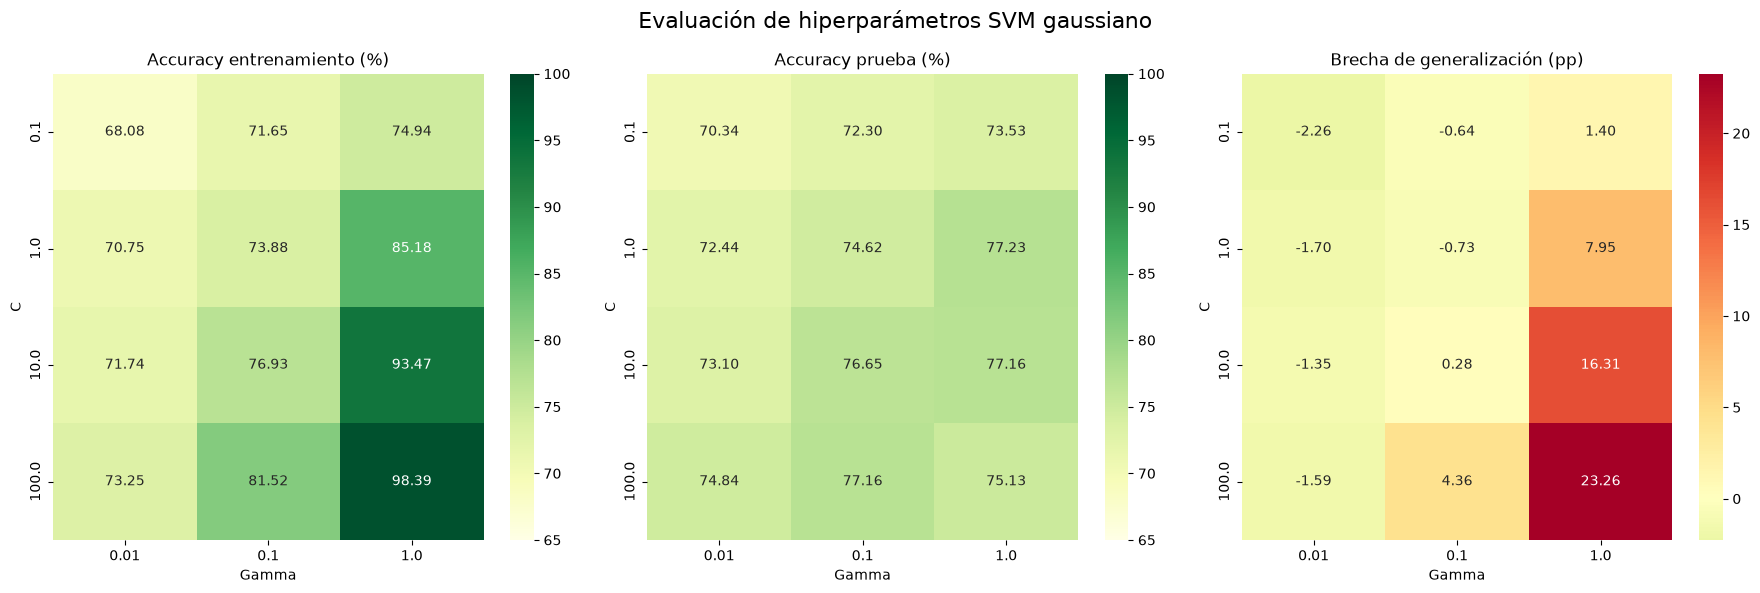

In [39]:
# Construcción de las matrices

malla_train = df_malla.pivot(
    index="C",
    columns="Gamma",
    values="Accuracy entrenamiento"
)

malla_test = df_malla.pivot(
    index="C",
    columns="Gamma",
    values="Accuracy prueba"
)

malla_brecha = df_malla.pivot(
    index="C",
    columns="Gamma",
    values="Brecha"
)

# Creación de los mapas de calor

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.heatmap(
    malla_train * 100,
    annot=True,
    fmt=".2f",
    cmap="YlGn",
    vmin=65,
    vmax=100,
    ax=axes[0]
)

axes[0].set_title("Accuracy entrenamiento (%)")

sns.heatmap(
    malla_test * 100,
    annot=True,
    fmt=".2f",
    cmap="YlGn",
    vmin=65,
    vmax=100,
    ax=axes[1]
)

axes[1].set_title("Accuracy prueba (%)")

sns.heatmap(
    malla_brecha * 100,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    center=0,
    ax=axes[2]
)

axes[2].set_title("Brecha de generalización (pp)")

for ax in axes:
    ax.set_xlabel("Gamma")
    ax.set_ylabel("C")

plt.suptitle(
    "Evaluación de hiperparámetros SVM gaussiano",
    fontsize=16
)

plt.tight_layout()
plt.show()

### 5.6. Identificación de la configuración con mayor exactitud

Se ordenan las configuraciones de los hiperparámetros
de acuerdo con su exactitud en el conjunto de prueba.

Se identifica la combinación de C y gamma que presenta
el mayor porcentaje de aciertos observado.

También se analiza su brecha de generalización para
determinar si existen indicios de sobreajuste.

In [40]:
mejor_resultado = df_malla.loc[
    df_malla["Accuracy prueba"].idxmax()
]

mejor_C = mejor_resultado["C"]

mejor_gamma = mejor_resultado["Gamma"]

print(f"Mejor C: {mejor_C:g}")

print(f"Mejor Gamma: {mejor_gamma:g}")

print(
    f"Accuracy entrenamiento: "
    f"{mejor_resultado['Accuracy entrenamiento']:.2%}"
)

print(
    f"Accuracy prueba: "
    f"{mejor_resultado['Accuracy prueba']:.2%}"
)

print(
    f"Brecha: "
    f"{mejor_resultado['Brecha'] * 100:.2f} pp"
)

# Recuperar el modelo correspondiente

mejor_modelo_rbf = modelos_malla[
    (mejor_C, mejor_gamma)
]

Mejor C: 1
Mejor Gamma: 1
Accuracy entrenamiento: 85.18%
Accuracy prueba: 77.23%
Brecha: 7.95 pp


### 5.7. Identificación del sobreajuste

Se analiza el comportamiento del modelo SVM gaussiano
manteniendo gamma igual a 1 e incrementando los valores
del hiperparámetro C.

Se compara la evolución de la exactitud en entrenamiento
y prueba para identificar el punto en el que el modelo
comienza a ajustarse excesivamente a los datos de
entrenamiento.

El sobreajuste se manifiesta cuando la exactitud en
entrenamiento continúa aumentando, mientras que la
exactitud en prueba se mantiene estable o disminuye.

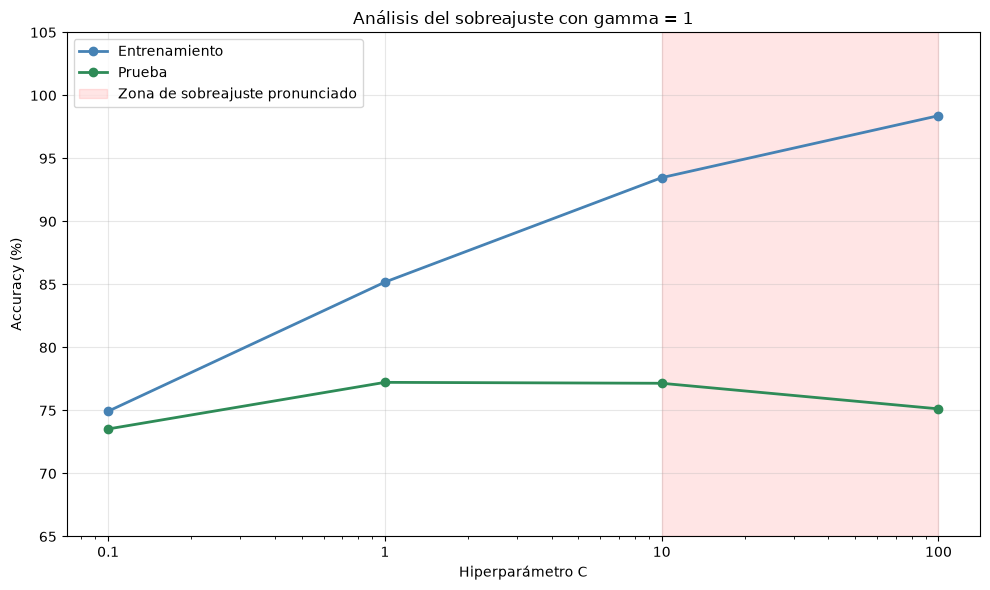

In [41]:
analisis_sobreajuste = df_malla[
    df_malla["Gamma"] == 1
].sort_values("C")

plt.figure(figsize=(10, 6))

plt.plot(
    analisis_sobreajuste["C"],
    analisis_sobreajuste["Accuracy entrenamiento"] * 100,
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Entrenamiento"
)

plt.plot(
    analisis_sobreajuste["C"],
    analisis_sobreajuste["Accuracy prueba"] * 100,
    marker="o",
    linewidth=2,
    color="seagreen",
    label="Prueba"
)

plt.xscale("log")

plt.xticks(
    valores_C,
    ["0.1", "1", "10", "100"]
)

plt.axvspan(
    10,
    100,
    color="red",
    alpha=0.1,
    label="Zona de sobreajuste pronunciado"
)

plt.title("Análisis del sobreajuste con gamma = 1")
plt.xlabel("Hiperparámetro C")
plt.ylabel("Accuracy (%)")
plt.ylim(65, 105)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.8. Comparación con el modelo gaussiano inicial

Se compara el desempeño del modelo SVM gaussiano inicial
con la configuración que obtuvo la mayor exactitud
en prueba durante la evaluación de hiperparámetros.

El objetivo es cuantificar la mejora obtenida mediante
la modificación de C y gamma, considerando también
la brecha de generalización de cada modelo.

In [42]:
comparacion_optimizacion = pd.DataFrame({
    "Modelo": [
        "SVM Gaussiano inicial",
        "SVM Gaussiano ajustado"
    ],

    "Accuracy entrenamiento": [
        acc_train_rbf_ampliado,
        mejor_resultado["Accuracy entrenamiento"]
    ],

    "Accuracy prueba": [
        acc_test_rbf_ampliado,
        mejor_resultado["Accuracy prueba"]
    ]
})

comparacion_optimizacion["Brecha"] = (
    comparacion_optimizacion["Accuracy entrenamiento"]
    - comparacion_optimizacion["Accuracy prueba"]
)

mejora_optimizacion = (
    mejor_resultado["Accuracy prueba"]
    - acc_test_rbf_ampliado
) * 100

print(
    f"Mejora en prueba: "
    f"{mejora_optimizacion:.2f} puntos porcentuales"
)

comparacion_optimizacion.style.format({
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}",
    "Brecha": "{:.2%}"
})

Mejora en prueba: 2.68 puntos porcentuales


,Modelo,Accuracy entrenamiento,Accuracy prueba,Brecha
0,SVM Gaussiano inicial,74.19%,74.55%,-0.35%
1,SVM Gaussiano ajustado,85.18%,77.23%,7.95%


### 5.9. Análisis del equilibrio entre exactitud y generalización

Se identifican configuraciones alternativas que presentan
una exactitud elevada en prueba y una menor diferencia
respecto al desempeño en entrenamiento.

El propósito es analizar si existen modelos que ofrezcan
un equilibrio favorable entre capacidad predictiva
y generalización, sin incrementar excesivamente
la complejidad del modelo.

In [43]:
configuraciones_equilibradas = df_malla[
    df_malla["Brecha"].abs() <= 0.05
].sort_values(
    "Accuracy prueba",
    ascending=False
)

configuraciones_equilibradas.style.format({
    "C": "{:g}",
    "Gamma": "{:g}",
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}",
    "Brecha": "{:.2%}"
}).highlight_max(
    subset=["Accuracy prueba"],
    color="lightgreen"
)

,C,Gamma,Accuracy entrenamiento,Accuracy prueba,Brecha
10,100,0.1,81.52%,77.16%,4.36%
7,10,0.1,76.93%,76.65%,0.28%
9,100,0.01,73.25%,74.84%,-1.59%
4,1,0.1,73.88%,74.62%,-0.73%
2,0.1,1,74.94%,73.53%,1.40%
6,10,0.01,71.74%,73.10%,-1.35%
3,1,0.01,70.75%,72.44%,-1.70%
1,0.1,0.1,71.65%,72.30%,-0.64%
0,0.1,0.01,68.08%,70.34%,-2.26%


### 5.10. Interpretación de los resultados

Se evaluaron 12 combinaciones de los hiperparámetros
C y gamma del modelo SVM gaussiano.

La configuración C=1 y gamma=1 obtuvo la mayor exactitud
observada en prueba, con un 77,23 %, y una exactitud en
entrenamiento del 85,18 %, presentando una brecha de
generalización de 7,95 puntos porcentuales.

Respecto al modelo gaussiano inicial, la exactitud en
prueba aumentó del 74,55 % al 77,23 %, lo que representa
una mejora de aproximadamente 2,68 puntos porcentuales.

Al mantener gamma=1 e incrementar C, se identificaron
indicios de sobreajuste desde C=1, los cuales se vuelven
más pronunciados a partir de C=10.

El caso más evidente corresponde a C=100 y gamma=1,
donde la exactitud en entrenamiento alcanzó el 98,39 %,
mientras que en prueba disminuyó al 75,13 %, generando
una brecha de 23,26 puntos porcentuales.

Por otra parte, la configuración C=10 y gamma=0.1
obtuvo una exactitud del 76,65 % en prueba y una brecha
de apenas 0,28 puntos porcentuales, constituyendo una
alternativa con un equilibrio favorable entre aprendizaje
y generalización.

Se concluye que incrementar los valores de C y gamma
no garantiza una mejora en la capacidad predictiva.
Una configuración excesivamente compleja puede generar
sobreajuste y reducir la capacidad del modelo para
clasificar nuevas observaciones.

Para una selección definitiva de hiperparámetros se
recomienda utilizar validación cruzada y reservar un
conjunto de prueba independiente.

## 6. Conteo e interpretación de los vectores de soporte

### 6.1. Definición de los vectores de soporte

Los vectores de soporte son las observaciones del conjunto
de entrenamiento que intervienen directamente en la
construcción de la frontera de decisión de un modelo SVM.

La cantidad de vectores de soporte permite analizar
las características de la separación entre las clases
y la complejidad del problema de clasificación.

Un número elevado de vectores de soporte puede estar
relacionado con el solapamiento entre las clases,
la dificultad de separación y la configuración
de los hiperparámetros del modelo.

En este apartado se analiza su cantidad y proporción
respecto al total de observaciones de entrenamiento.

### 6.2. Conteo de los vectores de soporte

Se identifica la cantidad de vectores de soporte utilizados
por los modelos SVM entrenados en los apartados anteriores.

Mediante el atributo n_support_ se obtiene la cantidad
de vectores de soporte correspondiente a cada clase:

- Clase 0: alojamientos baratos.
- Clase 1: alojamientos caros.

También se calcula el número total de vectores de soporte
y su proporción respecto al conjunto de entrenamiento.

In [44]:
print("SVM gaussiano ampliado")

print(
    "Vectores de soporte - Clase 0:",
    svm_rbf_ampliado.n_support_[0]
)

print(
    "Vectores de soporte - Clase 1:",
    svm_rbf_ampliado.n_support_[1]
)

total_vectores = svm_rbf_ampliado.n_support_.sum()

print("Total de vectores de soporte:", total_vectores)

print("Total de registros de entrenamiento:", len(y_train))

porcentaje_vectores = total_vectores / len(y_train)

print(f"Porcentaje de vectores de soporte: {porcentaje_vectores:.2%}")

SVM gaussiano ampliado
Vectores de soporte - Clase 0: 1663
Vectores de soporte - Clase 1: 1652
Total de vectores de soporte: 3315
Total de registros de entrenamiento: 5514
Porcentaje de vectores de soporte: 60.12%


### 6.3. Comparación de los vectores de soporte

Se compara la cantidad de vectores de soporte utilizados
por los diferentes modelos SVM desarrollados durante
la actividad.

Se consideran los modelos geográficos, los modelos con
variables ampliadas, los modelos sin escalado y las
configuraciones ajustadas mediante hiperparámetros.

El objetivo es identificar cómo las características
de cada modelo influyen en la cantidad de observaciones
utilizadas para construir la frontera de decisión.

In [45]:
modelos_analisis = {
    "Lineal geográfico": svm_lineal,
    "Gaussiano geográfico": svm_rbf,
    "Lineal ampliado": svm_lineal_ampliado,
    "Gaussiano ampliado": svm_rbf_ampliado,
    "Lineal sin escalado": svm_lineal_sin_escalado,
    "Gaussiano sin escalado": svm_rbf_sin_escalado,
    "Gaussiano ajustado": mejor_modelo_rbf,
    "Gaussiano C=10, Gamma=0.1": modelos_malla[(10, 0.1)],
    "Gaussiano C=100, Gamma=1": modelos_malla[(100, 1)]
}

resultados_vectores = []

for nombre, modelo in modelos_analisis.items():

    vectores_clase_0 = modelo.n_support_[0]

    vectores_clase_1 = modelo.n_support_[1]

    total = modelo.n_support_.sum()

    porcentaje = total / len(y_train)

    resultados_vectores.append({
        "Modelo": nombre,
        "Vectores clase 0": vectores_clase_0,
        "Vectores clase 1": vectores_clase_1,
        "Total vectores": total,
        "Total entrenamiento": len(y_train),
        "Porcentaje": porcentaje,
        "Convergencia": (
            "Sí" if modelo.fit_status_ == 0 else "No"
        )
    })

df_vectores = pd.DataFrame(resultados_vectores)

df_vectores.style.format({
    "Porcentaje": "{:.2%}"
}).highlight_max(
    subset=["Porcentaje"],
    color="lightcoral"
).highlight_min(
    subset=["Porcentaje"],
    color="lightgreen"
)

,Modelo,Vectores clase 0,Vectores clase 1,Total vectores,Total entrenamiento,Porcentaje,Convergencia
0,Lineal geográfico,2708,2708,5416,5514,98.22%,Sí
1,Gaussiano geográfico,2392,2388,4780,5514,86.69%,Sí
2,Lineal ampliado,1691,1693,3384,5514,61.37%,Sí
3,Gaussiano ampliado,1663,1652,3315,5514,60.12%,Sí
4,Lineal sin escalado,1678,1868,3546,5514,64.31%,No
5,Gaussiano sin escalado,2475,2471,4946,5514,89.70%,Sí
6,Gaussiano ajustado,1944,1794,3738,5514,67.79%,Sí
7,"Gaussiano C=10, Gamma=0.1",1583,1574,3157,5514,57.25%,Sí
8,"Gaussiano C=100, Gamma=1",1525,1471,2996,5514,54.33%,Sí


### 6.4. Visualización comparativa de los vectores de soporte

Se genera un gráfico de barras horizontales para representar
el porcentaje de vectores de soporte de cada modelo SVM.

Esta visualización permite comparar la proporción de
observaciones que intervienen en la construcción de
las fronteras de decisión.

También facilita la identificación de diferencias entre
los modelos geográficos, ampliados y ajustados mediante
hiperparámetros.

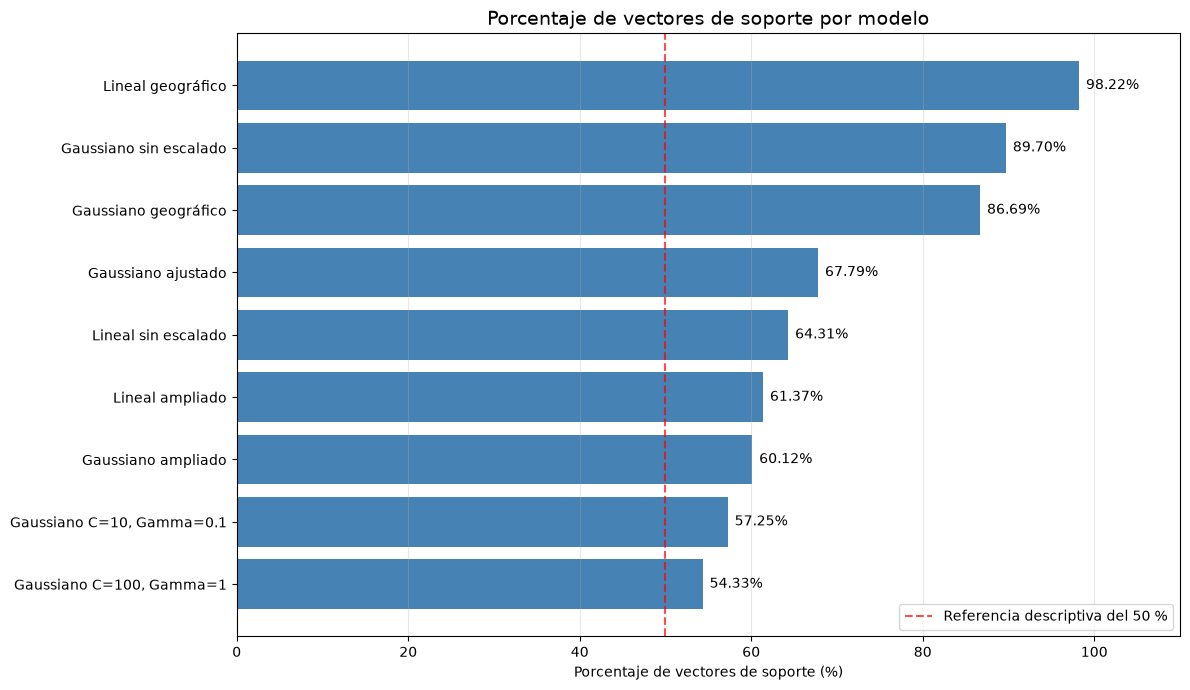

In [46]:
df_vectores_ordenado = df_vectores.sort_values(
    "Porcentaje",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    df_vectores_ordenado["Modelo"],
    df_vectores_ordenado["Porcentaje"] * 100,
    color="steelblue"
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=5
)

ax.set_title(
    "Porcentaje de vectores de soporte por modelo",
    fontsize=14
)

ax.set_xlabel("Porcentaje de vectores de soporte (%)")

ax.set_xlim(0, 110)

ax.axvline(
    50,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Referencia descriptiva del 50 %"
)

ax.grid(axis="x", alpha=0.3)

ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

### 6.5. Distribución de los vectores de soporte por clase

Se analiza la distribución de los vectores de soporte
correspondientes a las dos clases de la variable objetivo.

Se utiliza un gráfico de barras apiladas para identificar
la participación de los alojamientos caros y baratos
en la construcción de las fronteras de decisión.

El análisis permite observar si ambas clases tienen
una participación similar o si existen diferencias
en la cantidad de vectores de soporte utilizados.

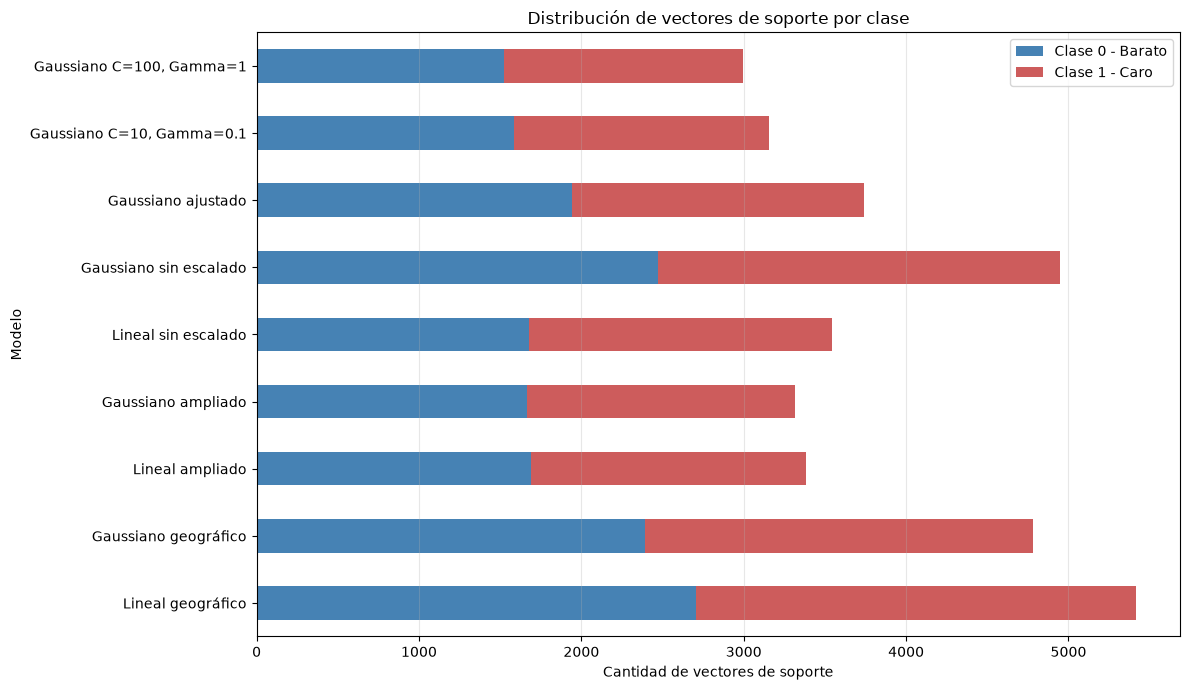

In [47]:
ax = df_vectores.set_index("Modelo")[
    ["Vectores clase 0", "Vectores clase 1"]
].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    color=["steelblue", "indianred"]
)

plt.title("Distribución de vectores de soporte por clase")

plt.xlabel("Cantidad de vectores de soporte")
plt.ylabel("Modelo")

plt.legend([
    "Clase 0 - Barato",
    "Clase 1 - Caro"
])

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.6. Representación geográfica de los vectores de soporte

Se representan las coordenadas geográficas de los
alojamientos del conjunto de entrenamiento.

Se identifican visualmente los vectores de soporte
correspondientes a los modelos SVM lineal y gaussiano.

Esta representación permite observar la distribución
espacial de las observaciones que intervienen en
la construcción de las fronteras de decisión.

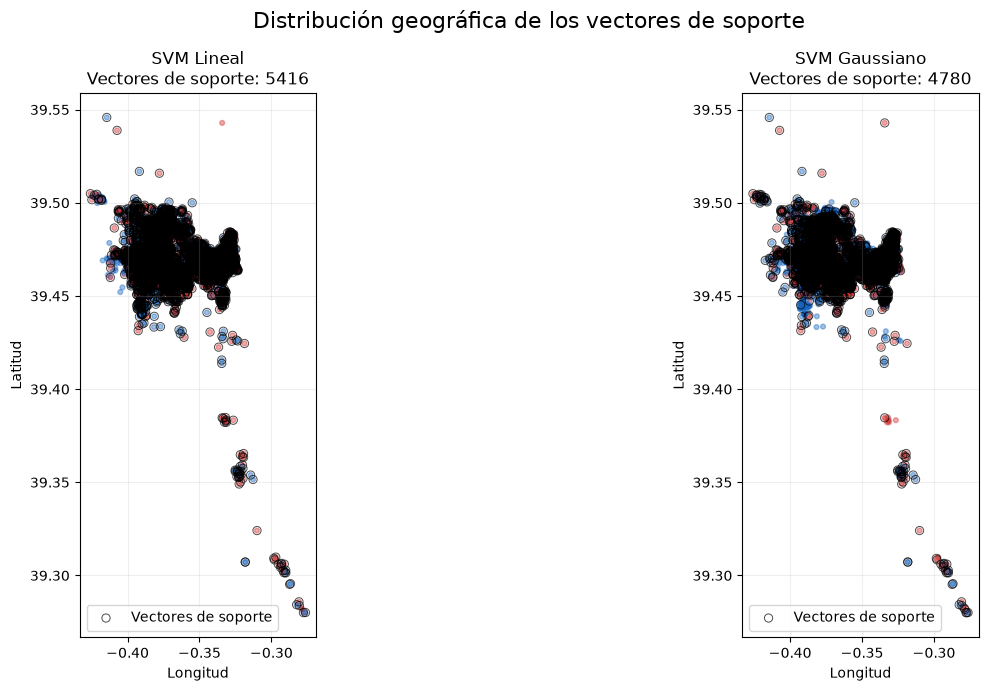

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

modelos_geo_soporte = [
    (svm_lineal, "SVM Lineal"),
    (svm_rbf, "SVM Gaussiano")
]

for ax, (modelo, titulo) in zip(
    axes,
    modelos_geo_soporte
):

    # Observaciones de entrenamiento
    ax.scatter(
        X_train["longitud"],
        X_train["latitud"],
        c=y_train,
        cmap=colores_puntos,
        s=12,
        alpha=0.4
    )

    # Recuperar las coordenadas de los vectores de soporte
    vectores = X_train.iloc[modelo.support_]

    # Resaltar los vectores de soporte
    ax.scatter(
        vectores["longitud"],
        vectores["latitud"],
        facecolors="none",
        edgecolors="black",
        s=35,
        linewidths=0.7,
        alpha=0.7,
        label="Vectores de soporte"
    )

    ax.set_title(
        f"{titulo}\n"
        f"Vectores de soporte: {len(vectores)}"
    )

    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")

    ax.set_aspect(
        1 / np.cos(np.radians(X["latitud"].mean()))
    )

    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Distribución geográfica de los vectores de soporte",
    fontsize=16
)

plt.tight_layout()
plt.show()

### 6.7. Influencia de los hiperparámetros C y gamma

Se analiza la cantidad de vectores de soporte utilizados
por las 12 configuraciones del modelo SVM gaussiano
evaluadas en el apartado anterior.

Se incorpora el porcentaje de vectores de soporte
a la tabla de resultados de los hiperparámetros.

El objetivo es identificar la relación entre los
hiperparámetros, la cantidad de vectores de soporte
y el desempeño predictivo del modelo.

In [49]:
df_malla["Total vectores"] = [
    modelos_malla[(fila["C"], fila["Gamma"])].n_support_.sum()
    for _, fila in df_malla.iterrows()
]

df_malla["Porcentaje vectores"] = (
    df_malla["Total vectores"] / len(y_train)
)

df_malla.style.format({
    "C": "{:g}",
    "Gamma": "{:g}",
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}",
    "Brecha": "{:.2%}",
    "Porcentaje vectores": "{:.2%}"
})

,C,Gamma,Accuracy entrenamiento,Accuracy prueba,Brecha,Total vectores,Porcentaje vectores
0,0.1,0.01,68.08%,70.34%,-2.26%,3965,71.91%
1,0.1,0.1,71.65%,72.30%,-0.64%,3598,65.25%
2,0.1,1,74.94%,73.53%,1.40%,4451,80.72%
3,1,0.01,70.75%,72.44%,-1.70%,3463,62.80%
4,1,0.1,73.88%,74.62%,-0.73%,3312,60.07%
5,1,1,85.18%,77.23%,7.95%,3738,67.79%
6,10,0.01,71.74%,73.10%,-1.35%,3333,60.45%
7,10,0.1,76.93%,76.65%,0.28%,3157,57.25%
8,10,1,93.47%,77.16%,16.31%,3303,59.90%
9,100,0.01,73.25%,74.84%,-1.59%,3263,59.18%


### 6.8. Mapa de calor de los vectores de soporte

Se construye un mapa de calor para visualizar el porcentaje
de vectores de soporte correspondiente a cada combinación
de los hiperparámetros C y gamma.

La representación permite complementar el análisis
del sobreajuste realizado anteriormente y comprender
cómo los hiperparámetros modifican las características
del modelo SVM gaussiano.

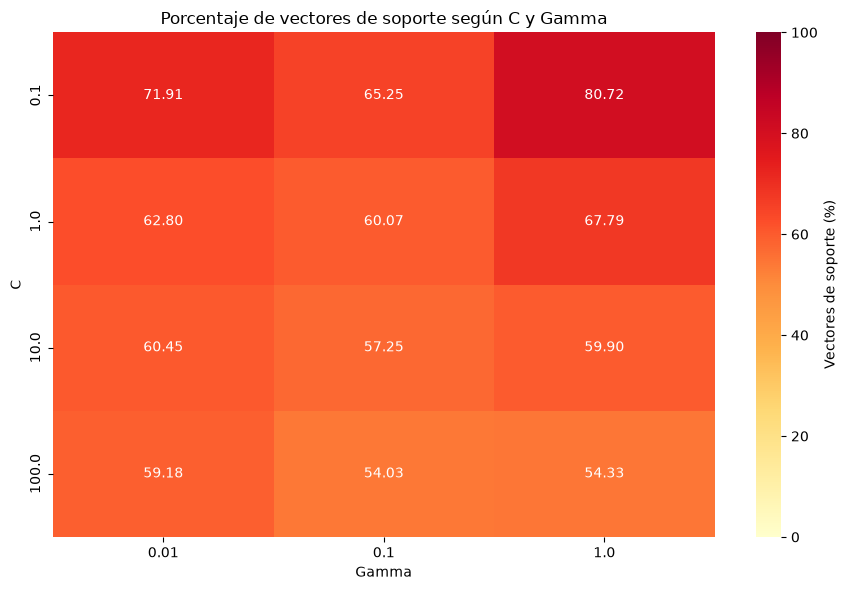

In [50]:
malla_vectores = df_malla.pivot(
    index="C",
    columns="Gamma",
    values="Porcentaje vectores"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    malla_vectores * 100,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Vectores de soporte (%)"
    }
)

plt.title(
    "Porcentaje de vectores de soporte según C y Gamma"
)

plt.xlabel("Gamma")
plt.ylabel("C")

plt.tight_layout()
plt.show()

### 6.10. Resumen de los resultados obtenidos

Se identifican los modelos con mayor y menor cantidad
de vectores de soporte.

También se analiza la proporción de vectores de soporte
del modelo gaussiano inicial, del modelo ajustado y
del modelo que presentó el mayor sobreajuste.

Los resultados permiten complementar la evaluación
del desempeño y la complejidad de los modelos.

In [51]:
# Identificar modelos que alcanzaron la convergencia

vectores_convergentes = df_vectores[
    df_vectores["Convergencia"] == "Sí"
]

mayor = vectores_convergentes.loc[
    vectores_convergentes["Porcentaje"].idxmax()
]

menor = vectores_convergentes.loc[
    vectores_convergentes["Porcentaje"].idxmin()
]

print("MODELO CON MAYOR PROPORCIÓN DE VECTORES")

print("Modelo:", mayor["Modelo"])
print("Total:", mayor["Total vectores"])
print(f"Porcentaje: {mayor['Porcentaje']:.2%}")

print("\nMODELO CON MENOR PROPORCIÓN DE VECTORES")

print("Modelo:", menor["Modelo"])
print("Total:", menor["Total vectores"])
print(f"Porcentaje: {menor['Porcentaje']:.2%}")

print("\nMODELOS GAUSSIANOS SELECCIONADOS")

for nombre, modelo in [
    ("Gaussiano inicial", svm_rbf_ampliado),
    ("Gaussiano ajustado", mejor_modelo_rbf),
    ("Gaussiano C=10, Gamma=0.1", modelos_malla[(10, 0.1)]),
    ("Gaussiano C=100, Gamma=1", modelos_malla[(100, 1)])
]:

    total = modelo.n_support_.sum()

    porcentaje = total / len(y_train)

    print(
        f"{nombre}: {total} vectores "
        f"({porcentaje:.2%})"
    )

MODELO CON MAYOR PROPORCIÓN DE VECTORES
Modelo: Lineal geográfico
Total: 5416
Porcentaje: 98.22%

MODELO CON MENOR PROPORCIÓN DE VECTORES
Modelo: Gaussiano C=100, Gamma=1
Total: 2996
Porcentaje: 54.33%

MODELOS GAUSSIANOS SELECCIONADOS
Gaussiano inicial: 3315 vectores (60.12%)
Gaussiano ajustado: 3738 vectores (67.79%)
Gaussiano C=10, Gamma=0.1: 3157 vectores (57.25%)
Gaussiano C=100, Gamma=1: 2996 vectores (54.33%)


### 6.11. Interpretación de los resultados

Los resultados evidencian una elevada proporción de vectores
de soporte en los modelos SVM analizados.

El modelo SVM lineal geográfico presentó la mayor cantidad,
con 5.416 vectores de soporte, equivalentes al 98,22 %
del conjunto de entrenamiento.

Este resultado sugiere que existe un considerable solapamiento
entre los alojamientos caros y baratos cuando se utiliza
únicamente la ubicación geográfica, dificultando su separación
mediante una frontera de decisión lineal.

El modelo gaussiano ampliado inicial utilizó 3.315 vectores
de soporte, equivalentes al 60,12 %, mientras que el modelo
gaussiano ajustado utilizó 3.738 vectores, correspondientes
al 67,79 %.

Por otra parte, la configuración C=10 y gamma=0.1 utilizó
3.157 vectores de soporte, equivalentes al 57,25 %,
presentando una alternativa con un equilibrio favorable
entre aprendizaje y generalización.

El modelo con C=100 y gamma=1 presentó la menor proporción,
con 2.996 vectores de soporte, equivalentes al 54,33 %.
Sin embargo, esta configuración presentó el mayor sobreajuste
en el análisis de hiperparámetros.

Esto demuestra que una menor cantidad de vectores de soporte
no garantiza una mejor capacidad de generalización.

En conclusión, los modelos analizados utilizan una proporción
considerable de las observaciones como vectores de soporte,
lo que es compatible con la complejidad del problema y la
dificultad de separar claramente los alojamientos caros
y baratos.

La cantidad de vectores de soporte debe interpretarse
conjuntamente con la exactitud en entrenamiento, la exactitud
en prueba y la brecha de generalización.

## 7. Conclusiones generales

### 7.1. Resumen del desempeño de los modelos

Se consolidan los principales resultados obtenidos durante
el desarrollo de la actividad, considerando la incorporación
de variables predictoras, el escalado y el ajuste de
hiperparámetros.

El propósito es identificar la evolución del desempeño
predictivo de los modelos SVM y establecer las principales
conclusiones del análisis.

In [52]:
resumen_final = pd.DataFrame({
    "Modelo": [
        "Lineal geográfico",
        "Gaussiano geográfico",
        "Lineal ampliado",
        "Gaussiano ampliado sin escalado",
        "Gaussiano ampliado con escalado",
        "Gaussiano ajustado",
        "Gaussiano C=10, Gamma=0.1",
        "Gaussiano C=100, Gamma=1"
    ],

    "Accuracy entrenamiento": [
        acc_train_lineal,
        acc_train_rbf,
        acc_train_lineal_ampliado,
        acc_train_rbf_sin,
        acc_train_rbf_ampliado,
        mejor_resultado["Accuracy entrenamiento"],
        modelos_malla[(10, 0.1)].score(
            X_train_ampliado_scaled, y_train
        ),
        modelos_malla[(100, 1)].score(
            X_train_ampliado_scaled, y_train
        )
    ],

    "Accuracy prueba": [
        acc_test_lineal,
        acc_test_rbf,
        acc_test_lineal_ampliado,
        acc_test_rbf_sin,
        acc_test_rbf_ampliado,
        mejor_resultado["Accuracy prueba"],
        modelos_malla[(10, 0.1)].score(
            X_test_ampliado_scaled, y_test
        ),
        modelos_malla[(100, 1)].score(
            X_test_ampliado_scaled, y_test
        )
    ],

    "Vectores de soporte": [
        svm_lineal.n_support_.sum(),
        svm_rbf.n_support_.sum(),
        svm_lineal_ampliado.n_support_.sum(),
        svm_rbf_sin_escalado.n_support_.sum(),
        svm_rbf_ampliado.n_support_.sum(),
        mejor_modelo_rbf.n_support_.sum(),
        modelos_malla[(10, 0.1)].n_support_.sum(),
        modelos_malla[(100, 1)].n_support_.sum()
    ]
})

resumen_final["Brecha"] = (
    resumen_final["Accuracy entrenamiento"]
    - resumen_final["Accuracy prueba"]
)

resumen_final["Porcentaje vectores"] = (
    resumen_final["Vectores de soporte"] / len(y_train)
)

resumen_final.style.format({
    "Accuracy entrenamiento": "{:.2%}",
    "Accuracy prueba": "{:.2%}",
    "Brecha": "{:.2%}",
    "Porcentaje vectores": "{:.2%}"
}).highlight_max(
    subset=["Accuracy prueba"],
    color="lightgreen"
).highlight_max(
    subset=["Brecha"],
    color="lightcoral"
)

,Modelo,Accuracy entrenamiento,Accuracy prueba,Vectores de soporte,Brecha,Porcentaje vectores
0,Lineal geográfico,49.47%,49.67%,5416,-0.20%,98.22%
1,Gaussiano geográfico,59.45%,62.87%,4780,-3.42%,86.69%
2,Lineal ampliado,70.51%,72.01%,3384,-1.50%,61.37%
3,Gaussiano ampliado sin escalado,60.55%,57.94%,4946,2.61%,89.70%
4,Gaussiano ampliado con escalado,74.19%,74.55%,3315,-0.35%,60.12%
5,Gaussiano ajustado,85.18%,77.23%,3738,7.95%,67.79%
6,"Gaussiano C=10, Gamma=0.1",76.93%,76.65%,3157,0.28%,57.25%
7,"Gaussiano C=100, Gamma=1",98.39%,75.13%,2996,23.26%,54.33%


### 7.2. Conclusiones generales

1. Preparación de los datos

El proceso de limpieza permitió obtener una base de datos
de 6.893 alojamientos, utilizando la mediana de 101 euros
como referencia para establecer una clasificación binaria
entre alojamientos caros y baratos.

2. Influencia de la ubicación geográfica

El modelo SVM gaussiano presentó un mejor desempeño que
el modelo lineal al utilizar únicamente latitud y longitud,
alcanzando una exactitud en prueba del 62,87 %.

Esto sugiere la existencia de patrones geográficos no
lineales relacionados con el precio de los alojamientos.

3. Incorporación de nuevas variables

La incorporación del tipo de alojamiento y las demás
variables numéricas permitió incrementar la capacidad
predictiva del modelo gaussiano del 62,87 % al 74,55 %,
demostrando la importancia de considerar características
adicionales a la ubicación geográfica.

4. Importancia del escalado

La estandarización de las variables permitió incrementar
la exactitud en prueba del modelo gaussiano del 57,94 %
al 74,55 %, lo que representa una mejora de 16,61 puntos
porcentuales.

Este resultado evidencia la sensibilidad del kernel
gaussiano a las diferentes escalas de las variables.

5. Ajuste de hiperparámetros y sobreajuste

La evaluación de 12 combinaciones de C y gamma permitió
identificar que la configuración C=1 y gamma=1 obtuvo
la mayor exactitud observada en prueba, con un 77,23 %.

Sin embargo, al incrementar excesivamente los valores
de los hiperparámetros se evidenció sobreajuste,
especialmente con C=100 y gamma=1.

6. Vectores de soporte

El modelo lineal geográfico utilizó el 98,22 % de las
observaciones de entrenamiento como vectores de soporte,
lo que sugiere una elevada dificultad para separar los
alojamientos utilizando únicamente su ubicación.

Asimismo, se comprobó que una menor cantidad de vectores
de soporte no garantiza una mejor generalización.

### Conclusión final

Los modelos SVM con kernel gaussiano constituyen una
alternativa adecuada para la clasificación del precio
de los alojamientos Airbnb en Valencia.

La incorporación de variables relevantes, la estandarización
y el ajuste de hiperparámetros permitieron mejorar
progresivamente la capacidad predictiva.

La configuración C=1 y gamma=1 obtuvo la mayor exactitud
observada en prueba. No obstante, la configuración C=10
y gamma=0.1 constituye una alternativa interesante debido
a su exactitud del 76,65 % y su reducida brecha de
generalización de 0,28 puntos porcentuales.

Para seleccionar definitivamente el modelo se recomienda
aplicar validación cruzada y utilizar un conjunto de
prueba independiente.